<a href="https://colab.research.google.com/github/Andrian0s/ML4NLP1-2026-Tutorial-Notebooks/blob/main/lectures_supplementary_code_samples/autodiff_mermaid.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Automatic differentiation: computation graphs

This notebook requests diagrams from the [Autodiff Visualizer Hugging Face Space](https://huggingface.co/spaces/simon-clmtd/autodiff-visualizer). The Space evaluates each expression and generates the graph; the notebook displays the returned PNG. An internet connection is required.

Read solid arrows upward for the forward values and dashed arrows downward for gradients. Pink nodes show the local derivative at each operation. When an input feeds several paths, its gradient combines the contributions from those paths.


In [1]:
%pip install gradio_client

Note: you may need to restart the kernel to use updated packages.


In [2]:
from gradio_client import Client
from IPython.display import Image, display

client = Client("simon-clmtd/autodiff-visualizer")

def show_graph(expr, vals):
    png_path = client.predict(
        expr=expr,
        vals=vals,
        mode="Forward & Backward",
        notation="∂(...) / ∂x [Mathbook]",
        api_name="/generate_png",
    )
    display(Image(filename=png_path))

Loaded as API: https://simon-clmtd-autodiff-visualizer.hf.space


## 1. Multiplication: $o = x y$

The local derivatives are $\partial o/\partial x = y$ and $\partial o/\partial y = x$. At $x=2$ and $y=3$, the output is $6$ and the input gradients are $3$ and $2$.


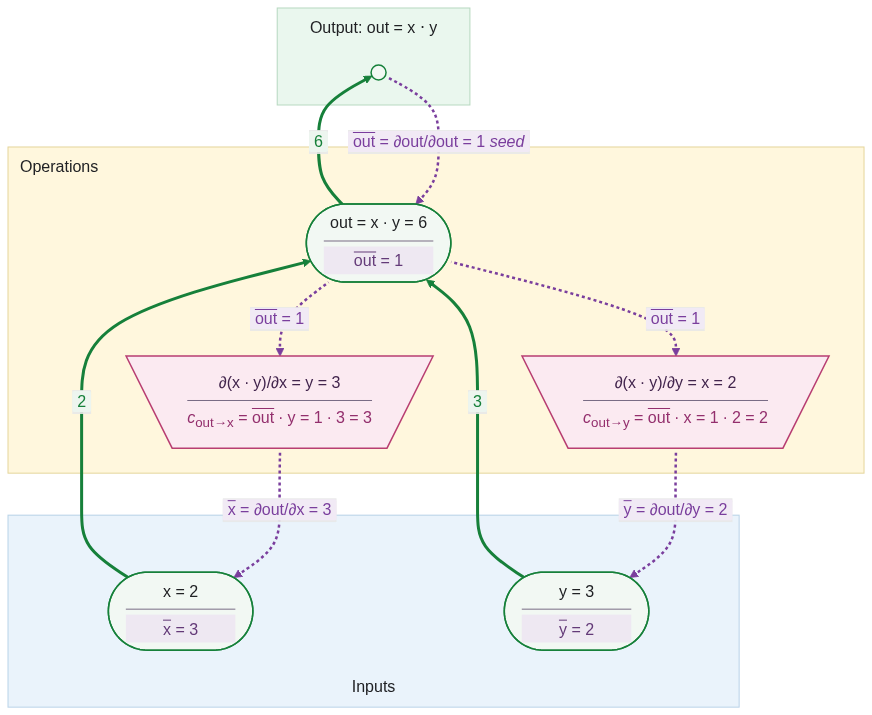

In [3]:
show_graph("x * y", "x=2, y=3")

## 2. A composite graph: $o = x^2 + y$

The gradient passes through the addition and then the squaring operation. At $x=3$ and $y=4$, $o=13$, $\partial o/\partial x=6$, and $\partial o/\partial y=1$.


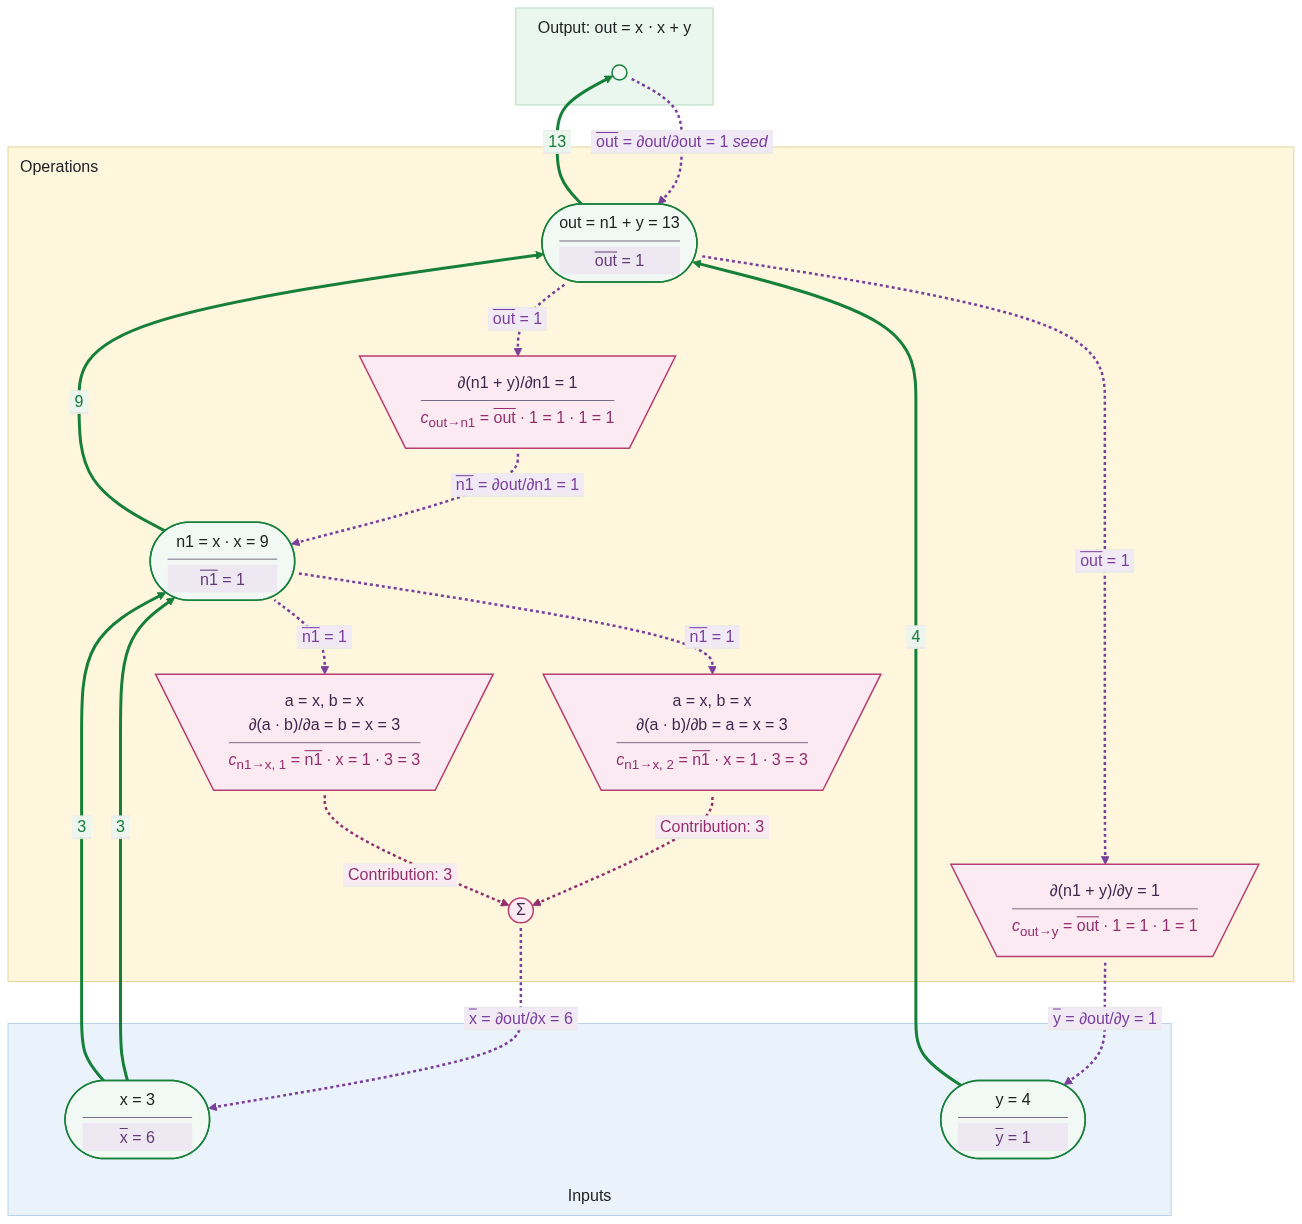

In [4]:
show_graph("(x * x) + y", "x=3, y=4")

## 3. Multiple paths: $z = x^2 y + (y + 2)$

Here $y$ influences the output through two paths. At $x=3$ and $y=4$, $z=42$, $\partial z/\partial x=24$, and $\partial z/\partial y=10$.


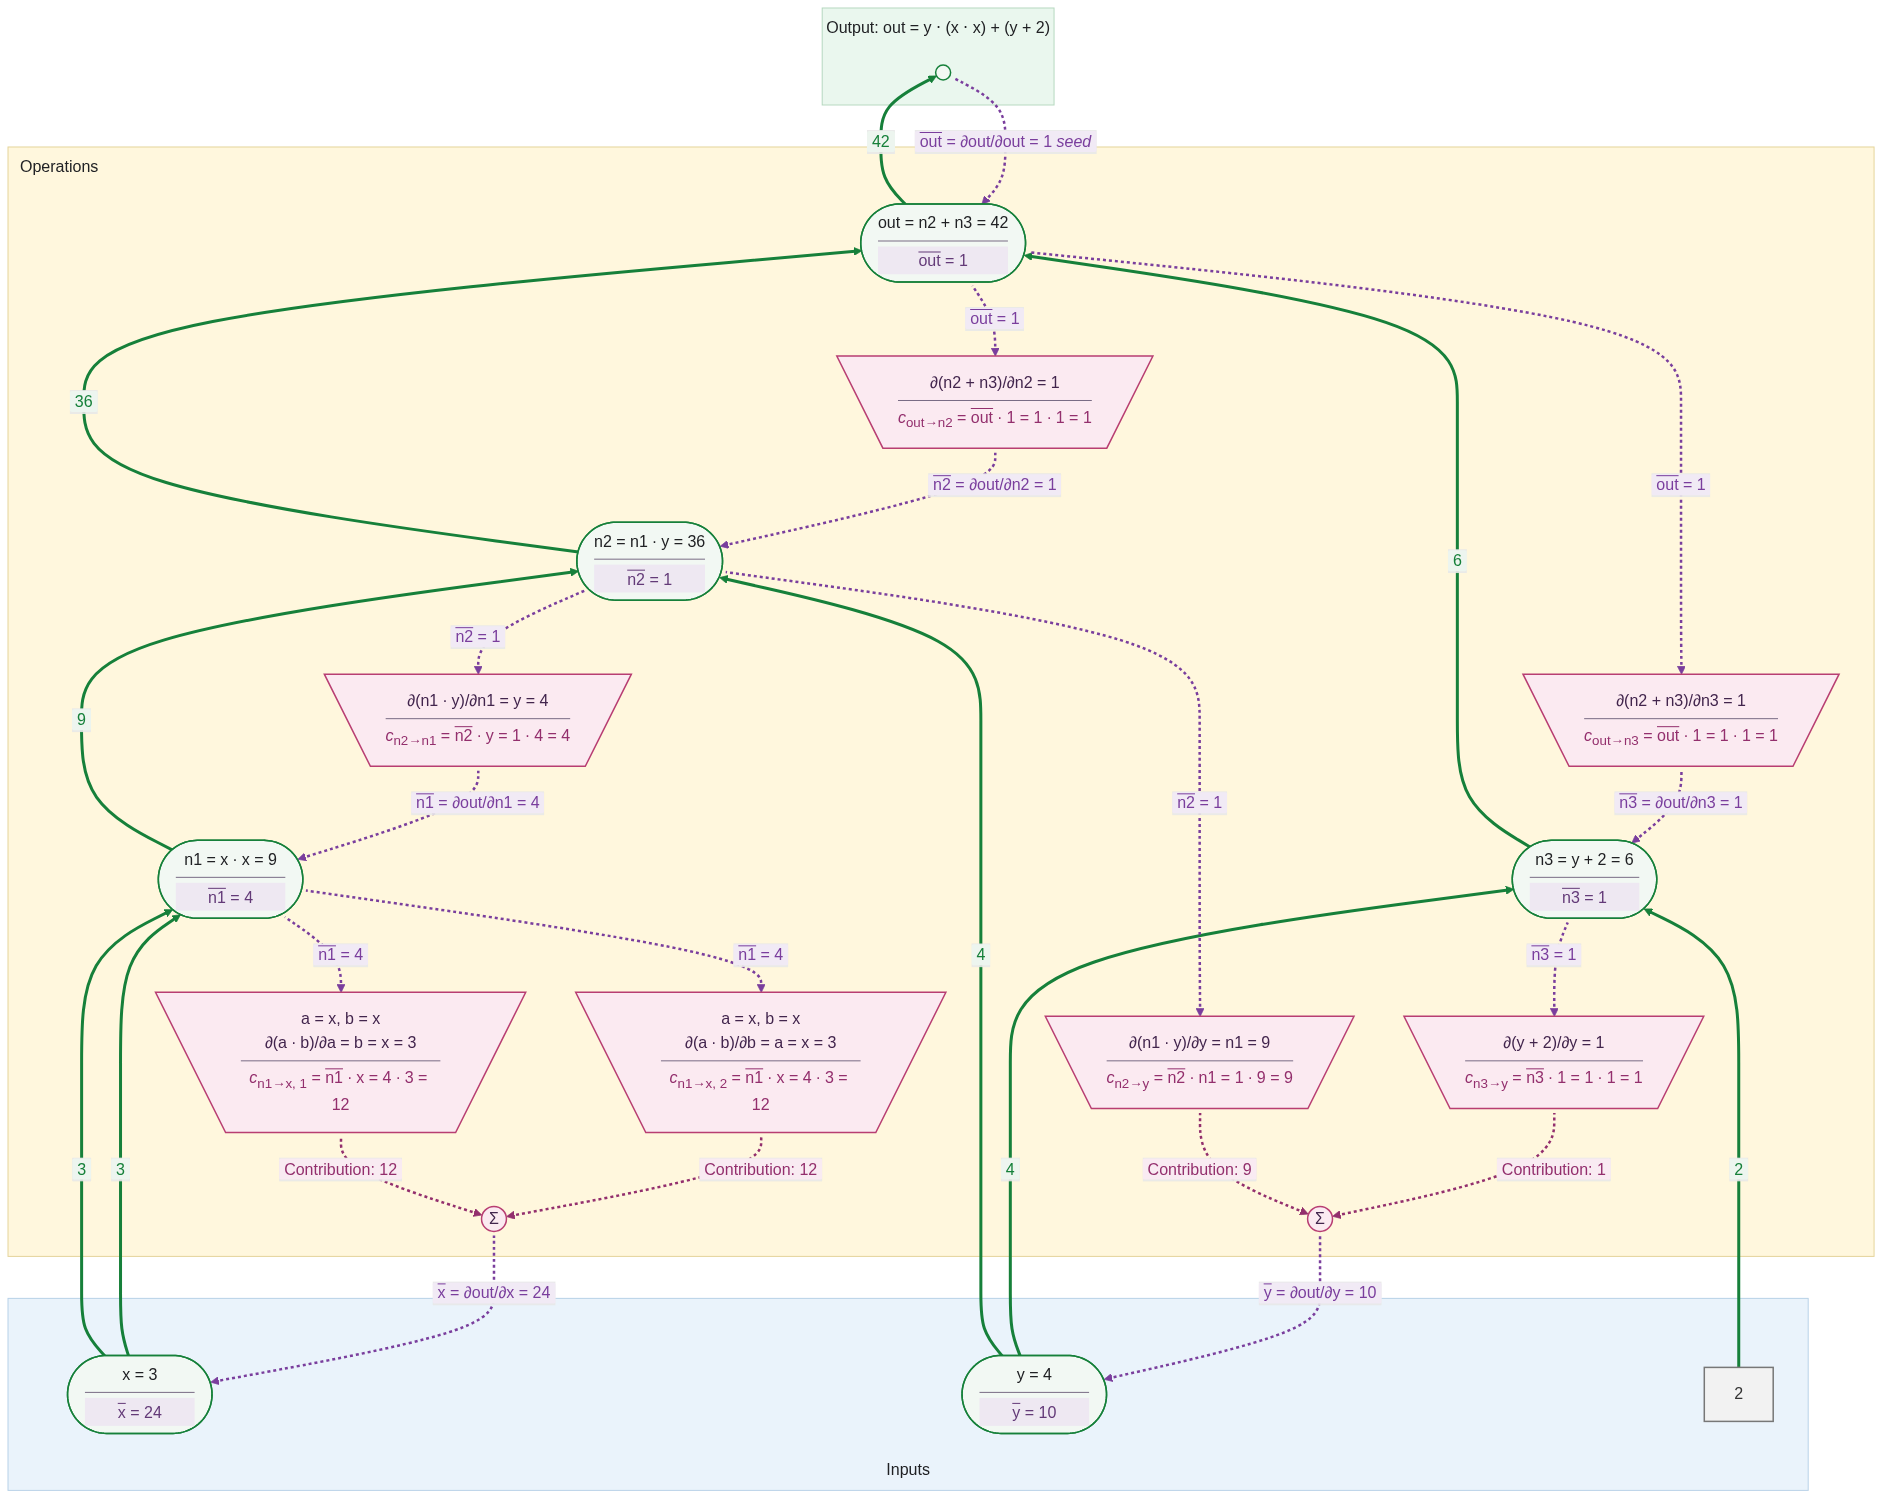

In [5]:
show_graph("(x * x) * y + (y + 2)", "x=3, y=4")

## 4. Nested expression: $L = ((x_1+x_2)x_3)^2$

At $x_1=1$, $x_2=2$, and $x_3=3$, the output is $81$. Each input gradient is $54$.


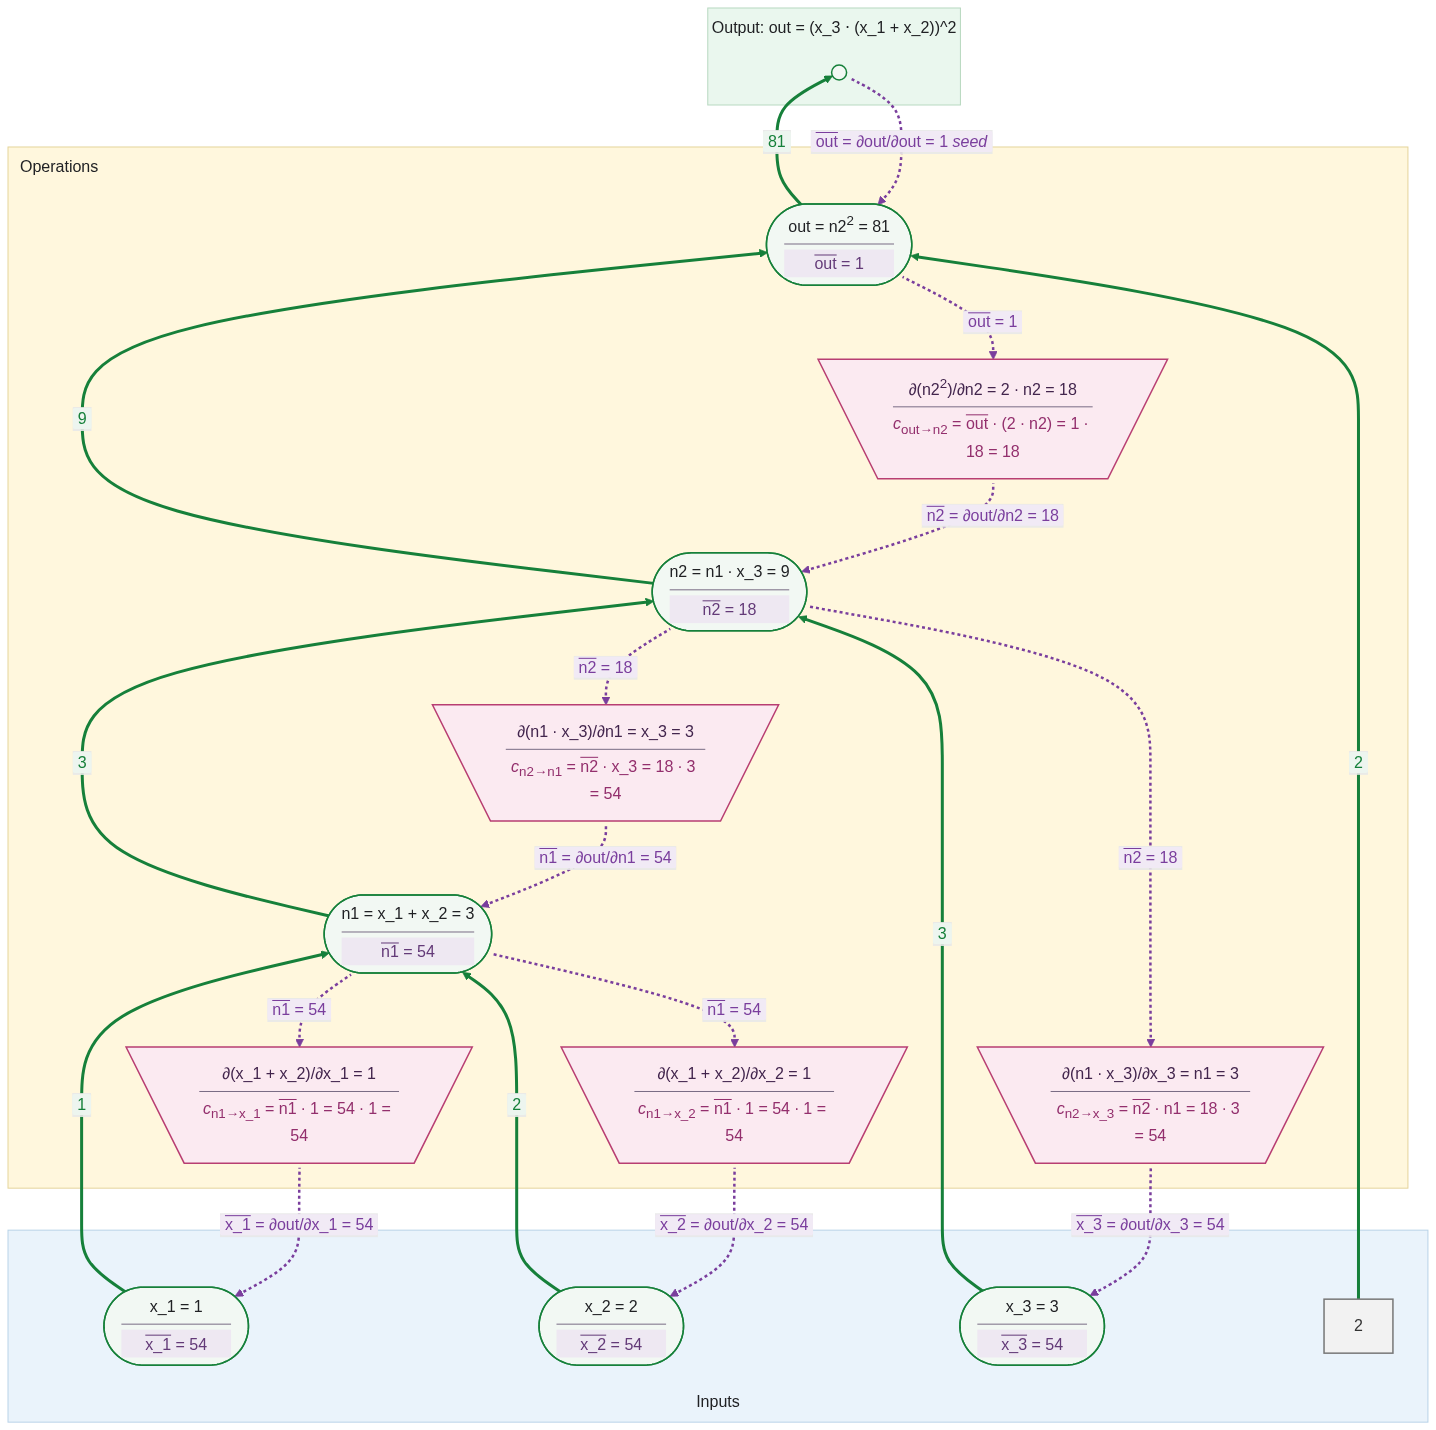

In [6]:
show_graph("((x_1 + x_2) * x_3)**2", "x_1=1, x_2=2, x_3=3")

## 5. Step-by-step walkthrough

The Space can also return an HTML trace. This example revisits $z=x^2y+(y+2)$ so you can compare each step with the graph above.


In [7]:
from IPython.display import HTML

walkthrough = client.predict(
    "(x * x) * y + (y + 2)",
    "x=3, y=4",
    "Forward & Backward",
    "∂(...) / ∂x [Mathbook]",
    api_name="/generate_walkthrough",
)
display(HTML(walkthrough))


Try changing an expression or its values above. The Space also provides `/generate_svg`, `/generate_pdf`, and `/generate_mermaid` endpoints for other forms of the same result.
